<a href="https://colab.research.google.com/github/Vinit-Rabadiya/pmi-gene-expression-analysis/blob/main/bioinformatics_pmi_gene_expression_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Post-Mortem Ischemic Time and Gene Expression in Human Skeletal Muscle
**Group 7 | ICS 4301 Computing for Bioinformatics**

**Research question:** Does post-mortem ischemic time systematically alter gene expression in skeletal muscle, and can expression predict ischemic time better than RNA quality alone?

**Data:** GTEx v11 bulk RNA-seq, skeletal muscle (TPM), with sample attributes. Ischemic time is `SMTSISCH` (minutes) and RNA integrity is `SMRIN`.

**Notes**
- Run the notebook from top to bottom. Each stage reads the files named under "Input" and writes the files named under "Output".
- Stage 1 builds the clean dataset. The later stages load it from `data/processed/`.
- Use the shared train/test split created after Stage 1 in every stage.
- Anything learned from the data, such as which genes are significant, must be learned from the training samples only.
- Large data files stay in Drive. Only code and small results go to GitHub.

# Setup

In [48]:
import os, glob, gzip
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42                      # one seed for the whole project
np.random.seed(SEED)

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

def find_project_folder():
    if not IN_COLAB:
        return os.environ.get('PROJECT_DIR', '.')
    default = '/content/drive/MyDrive/pmi-gene-expression-analysis'
    shared = glob.glob('/content/drive/Shareddrives/*/pmi-gene-expression-analysis')

    # Check existing folders without creating empty placeholders
    for c in [default] + shared:
        if os.path.isdir(c):
            return c

    raise FileNotFoundError(
        'Project folder "pmi-gene-expression-analysis" not found in My Drive or Shareddrives.\n'
        'If you expected the group folder:\n'
        '1. Open the shared folder in Google Drive web interface.\n'
        '2. Click "Organize" (or three dots) -> "Add shortcut".\n'
        '3. Select "My Drive" and save it there, then rerun this cell.'
    )

PROJECT = find_project_folder()
RAW = f'{PROJECT}/data/raw'
PROCESSED = f'{PROJECT}/data/processed'

# Only assert paths exist; do not automatically create them if they do not exist
assert os.path.isdir(RAW), f'Data raw folder does not exist: {RAW}'
assert os.path.isdir(PROCESSED), f'Data processed folder does not exist: {PROCESSED}'
print('Project folder verified:', PROJECT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder verified: /content/drive/MyDrive/pmi-gene-expression-analysis


# Stage 1: Data acquisition and subset extraction

**Input** (in `data/raw/`)
- GTEx v11 skeletal muscle TPM file, for example `gene_tpm_adult_gtex_v11_muscle_skeletal.gct.gz` (uploaded by hand)
- `GTEx_Analysis_v11_Annotations_SampleAttributesDS.txt` (downloaded in step 1.1)

**Output** (in `data/processed/`)
- `muscle_tpm.parquet`: genes x samples TPM matrix
- `muscle_metadata.csv`: one row per sample, in the same order as the matrix columns
- `gene_annotation.csv`: Ensembl ID to gene symbol
- `data_card.txt`: counts and ranges for the report

## 1.1 Download the sample attributes file
The file is only downloaded if it is not already in the raw folder. If the download fails, save the file in your browser with Ctrl+S and upload it to `data/raw/`.

In [49]:
import urllib.request

ATTR_NAME = 'GTEx_Analysis_v11_Annotations_SampleAttributesDS.txt'
ATTR_URL = f'https://storage.googleapis.com/adult-gtex/annotations/v11/metadata-files/{ATTR_NAME}'
attr_dest = f'{RAW}/{ATTR_NAME}'

if os.path.exists(attr_dest) and os.path.getsize(attr_dest) > 0:
    print(f'Already in Drive: {ATTR_NAME}')
else:
    try:
        urllib.request.urlretrieve(ATTR_URL, attr_dest)
        print(f'Downloaded: {ATTR_NAME} ({os.path.getsize(attr_dest)/1e6:.1f} MB)')
    except Exception as e:
        if os.path.exists(attr_dest):
            os.remove(attr_dest)                     # do not keep a half-written file
        print(f'Could not download {ATTR_NAME}: {e}')
        print('Download it in your browser, save it with Ctrl+S, and upload it to the raw folder.')

Already in Drive: GTEx_Analysis_v11_Annotations_SampleAttributesDS.txt


## 1.2 Locate the raw files
Files are found by name pattern, so they do not need to be renamed.

In [50]:
def find_one(patterns):
    for p in patterns:                               # earlier patterns take priority
        hits = sorted(glob.glob(f'{RAW}/{p}'))
        if hits:
            return hits[0]
    raise FileNotFoundError(f'No file matching {patterns} in {RAW}. Upload it and rerun.')

EXPR_FILE = find_one(['*muscle*skeletal*.gz', 'muscle_tpm*.gz'])
ATTR_FILE = find_one(['*SampleAttributesDS*', 'sample_attributes*'])

for label, f in [('Expression', EXPR_FILE), ('Sample attributes', ATTR_FILE)]:
    print(f'{label:20s}', os.path.basename(f), f'{os.path.getsize(f)/1e6:.1f} MB')

Expression           gene_tpm_adult_gtex_v11_muscle_skeletal.gct.gz 100.2 MB
Sample attributes    GTEx_Analysis_v11_Annotations_SampleAttributesDS.txt 38.5 MB


## 1.3 Load the sample attributes and keep skeletal muscle
Only the columns that are needed are read. `SAMPID` is the key that links each row to a column of the expression file.

In [51]:
ATTR_COLS = ['SAMPID', 'SMTS', 'SMTSD', 'SMRIN', 'SMTSISCH', 'SMAFRZE', 'SMGEBTCH', 'SMCENTER']
header = pd.read_csv(ATTR_FILE, sep='\t', nrows=0).columns
missing_cols = [c for c in ('SAMPID', 'SMTSD', 'SMRIN', 'SMTSISCH') if c not in header]
assert not missing_cols, f'Required columns missing from the attributes file: {missing_cols}'

attr = pd.read_csv(ATTR_FILE, sep='\t', usecols=[c for c in ATTR_COLS if c in header], low_memory=False)
print('Attribute rows                      :', len(attr))

muscle = attr[attr['SMTSD'] == 'Muscle - Skeletal'].copy()
print('Muscle - Skeletal rows (all assays) :', len(muscle))

Attribute rows                      : 48231
Muscle - Skeletal rows (all assays) : 2352


## 1.4 Read the expression matrix
The GCT file has two header lines, then one row per gene with the gene ID (`Name`), the gene symbol (`Description`) and one column per sample. Values are stored as `float32` to halve the memory use.

In [52]:
with gzip.open(EXPR_FILE, 'rt') as f:
    gct_version = f.readline().strip()
    dims = f.readline().split()
    columns = f.readline().rstrip('\n').split('\t')
print('GCT version:', gct_version, '| declared genes x samples:', dims)

dtypes = {c: 'float32' for c in columns[2:]}
dtypes.update({'Name': 'string', 'Description': 'string'})
expr_raw = pd.read_csv(EXPR_FILE, sep='\t', skiprows=2, dtype=dtypes, compression='gzip')

gene_annot = expr_raw[['Name', 'Description']].rename(columns={'Name': 'gene_id', 'Description': 'gene_symbol'})
expr_raw = expr_raw.drop(columns='Description').set_index('Name')
expr_raw.index.name = 'gene_id'
print('Expression matrix (genes x samples):', expr_raw.shape)
print('Memory used: %.0f MB' % (expr_raw.memory_usage(deep=True).sum() / 1e6))

GCT version: #1.2 | declared genes x samples: ['74628', '818']
Expression matrix (genes x samples): (74628, 818)
Memory used: 249 MB


## 1.5 Match samples and build the metadata table
Samples are matched on `SAMPID`, not on the tissue label alone, because only some muscle rows in the attributes file have RNA-seq expression data.

In [53]:
expr_ids = list(expr_raw.columns)
meta_raw = muscle.set_index('SAMPID').reindex(expr_ids)     # same order as the expression columns

n_no_attr = int(meta_raw['SMTSD'].isna().sum())
print(f'Expression samples            : {len(expr_ids)}')
print(f'With an attributes row        : {len(expr_ids) - n_no_attr}')
if n_no_attr:
    print(f'WARNING: {n_no_attr} expression samples have no skeletal muscle row in the attributes file.')
    print('         Check that the attributes file is complete and is from the same GTEx release.')

meta_raw = meta_raw.rename(columns={'SMRIN': 'rin', 'SMTSISCH': 'ischemic_min'})
meta_raw['rin'] = pd.to_numeric(meta_raw['rin'], errors='coerce')
meta_raw['ischemic_min'] = pd.to_numeric(meta_raw['ischemic_min'], errors='coerce')
meta_raw['donor_id'] = meta_raw.index.to_series().str.split('-').str[:2].str.join('-')

print('\nMissing values:')
print(meta_raw[['rin', 'ischemic_min']].isna().sum())
print('Donors with more than one muscle sample:', meta_raw['donor_id'].duplicated().sum())

Expression samples            : 818
With an attributes row        : 818

Missing values:
rin             0
ischemic_min    0
dtype: int64
Donors with more than one muscle sample: 0


## 1.6 Filter to usable samples and run checks
A sample is kept only if it has both RIN and ischemic time. Nothing else is removed here, so any further filtering stays visible in the later stages.

In [54]:
usable = meta_raw['rin'].notna() & meta_raw['ischemic_min'].notna()
meta_clean = meta_raw[usable].copy()
expr_clean = expr_raw.loc[:, meta_clean.index]               # keep columns in the same order

assert list(expr_clean.columns) == list(meta_clean.index), 'Matrix and metadata are out of order'
assert expr_clean.index.is_unique, 'Duplicate gene IDs in the matrix'
assert not expr_clean.isna().any().any(), 'NaN values in the expression matrix'
assert (meta_clean['ischemic_min'] > 0).all(), 'Non-positive ischemic times found'

print(f'Samples kept : {len(meta_clean)} of {len(expr_ids)}')
print(f'Genes        : {expr_clean.shape[0]}')
print(meta_clean[['rin', 'ischemic_min']].describe().round(2))
print('\nCorrelation of RIN with ischemic time: %.3f' % meta_clean['rin'].corr(meta_clean['ischemic_min']))

Samples kept : 818 of 818
Genes        : 74628
          rin  ischemic_min
count  818.00        818.00
mean     7.94        630.27
std      0.64        365.57
min      5.50         35.00
25%      7.70        301.25
50%      8.00        573.00
75%      8.40        911.50
max      9.90       2075.00

Correlation of RIN with ischemic time: -0.152


## 1.7 Overview of the two key variables

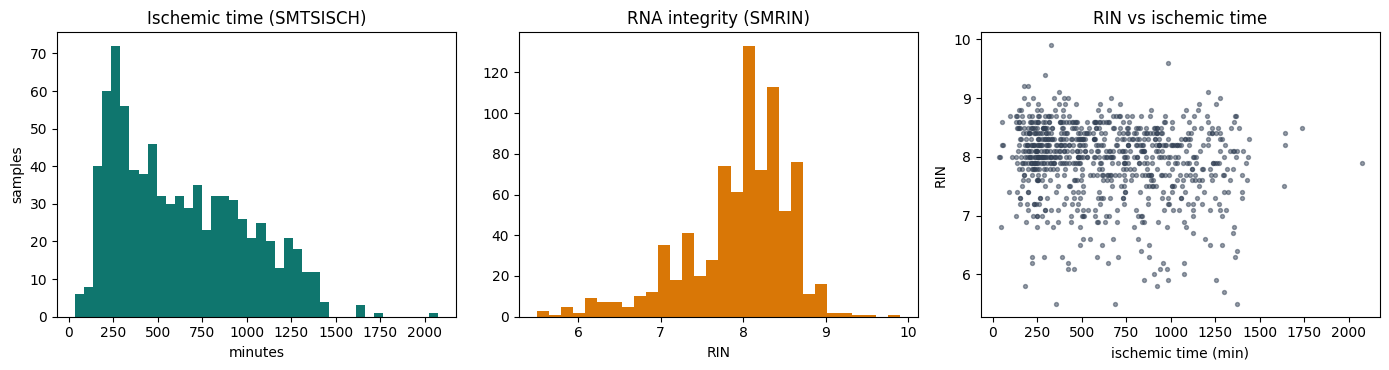

In [55]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].hist(meta_clean['ischemic_min'], bins=40, color='#0f766e')
ax[0].set(title='Ischemic time (SMTSISCH)', xlabel='minutes', ylabel='samples')
ax[1].hist(meta_clean['rin'], bins=30, color='#d97706')
ax[1].set(title='RNA integrity (SMRIN)', xlabel='RIN')
ax[2].scatter(meta_clean['ischemic_min'], meta_clean['rin'], s=8, alpha=0.5, color='#334155')
ax[2].set(title='RIN vs ischemic time', xlabel='ischemic time (min)', ylabel='RIN')
plt.tight_layout()
plt.savefig(f'{PROCESSED}/stage1_variable_overview.png', dpi=150)
plt.show()

## 1.8 Save the clean dataset

In [56]:
expr_clean.to_parquet(f'{PROCESSED}/muscle_tpm.parquet')
meta_clean.to_csv(f'{PROCESSED}/muscle_metadata.csv')
gene_annot.to_csv(f'{PROCESSED}/gene_annotation.csv', index=False)

card = [
    'Data card: GTEx skeletal muscle subset',
    f'Source expression file : {os.path.basename(EXPR_FILE)}',
    f'Source attributes file : {os.path.basename(ATTR_FILE)}',
    f'Genes                  : {expr_clean.shape[0]}',
    f'Samples kept           : {len(meta_clean)} of {len(expr_ids)} in the expression file',
    f'Ischemic time (min)    : {meta_clean.ischemic_min.min():.0f} to {meta_clean.ischemic_min.max():.0f}, median {meta_clean.ischemic_min.median():.0f}',
    f'RIN                    : {meta_clean.rin.min():.1f} to {meta_clean.rin.max():.1f}, median {meta_clean.rin.median():.1f}',
    f'RIN vs ischemic r      : {meta_clean.rin.corr(meta_clean.ischemic_min):.3f}',
]
open(f'{PROCESSED}/data_card.txt', 'w').write('\n'.join(card))
print('\n'.join(card))
print('\nSaved to', PROCESSED)
print(sorted(os.listdir(PROCESSED)))

Data card: GTEx skeletal muscle subset
Source expression file : gene_tpm_adult_gtex_v11_muscle_skeletal.gct.gz
Source attributes file : GTEx_Analysis_v11_Annotations_SampleAttributesDS.txt
Genes                  : 74628
Samples kept           : 818 of 818 in the expression file
Ischemic time (min)    : 35 to 2075, median 573
RIN                    : 5.5 to 9.9, median 8.0
RIN vs ischemic r      : -0.152

Saved to /content/drive/MyDrive/pmi-gene-expression-analysis/data/processed
['data_card.txt', 'gene_annotation.csv', 'muscle_metadata.csv', 'muscle_tpm.parquet', 'preprocessing_qc', 'shared_split.csv', 'stage1_variable_overview.png', 'stage2_filter_log.txt', 'stage2_split_integrity.csv', 'task1_variable_overview.png']


# Shared data for the later stages
Everything after Stage 1 starts from the saved files, so a stage can be run without repeating Stage 1.

| Name | What it is |
|---|---|
| `expr` | genes x samples TPM matrix |
| `meta` | one row per sample, in the same order as the columns of `expr`; key columns `rin` and `ischemic_min` |
| `gene_annot` | gene ID to gene symbol |
| `X` | `expr` transposed: samples x genes, ready for scikit-learn |
| `y` | the target: ischemic time in minutes |
| `train_ids`, `test_ids` | the fixed 80/20 split used by every stage |

## Load the clean dataset

In [57]:
expr = pd.read_parquet(f'{PROCESSED}/muscle_tpm.parquet')
meta = pd.read_csv(f'{PROCESSED}/muscle_metadata.csv', index_col=0)
gene_annot = pd.read_csv(f'{PROCESSED}/gene_annotation.csv')

assert list(expr.columns) == list(meta.index), 'Expression columns and metadata rows are out of order'
print(f'Genes: {expr.shape[0]} | samples: {expr.shape[1]}')

Genes: 74628 | samples: 818


## Shared train/test split
The split is created once and saved, then reused by every stage. It is made by sample, which is also a split by donor because no donor has more than one muscle sample (checked below).

In [58]:
assert meta['donor_id'].is_unique, 'A donor has more than one sample: split by donor instead of by sample'

SPLIT_FILE = f'{PROCESSED}/shared_split.csv'
if not os.path.exists(SPLIT_FILE):
    rng = np.random.RandomState(SEED)
    ids = np.array(meta.index)
    rng.shuffle(ids)
    n_test = int(round(0.2 * len(ids)))
    pd.DataFrame({'SAMPID': ids, 'set': ['test'] * n_test + ['train'] * (len(ids) - n_test)}).to_csv(SPLIT_FILE, index=False)
    print('Created the shared split:', SPLIT_FILE)

split = pd.read_csv(SPLIT_FILE, index_col=0)['set']
split = split.reindex(meta.index)
assert split.notna().all(), 'The saved split does not cover every sample. Delete shared_split.csv only if the group agrees.'

train_ids = split[split == 'train'].index
test_ids = split[split == 'test'].index

X = expr.T
y = meta['ischemic_min']
print(f'Train: {len(train_ids)} | test: {len(test_ids)}')

Train: 654 | test: 164


In [59]:
# Shared Split — Leakage Awareness & Integrity Audit

train_set = set(train_ids)
test_set = set(test_ids)

assert train_set.isdisjoint(test_set), \
    "LEAKAGE: Samples appear in both partitions!"

assert train_set | test_set == set(meta.index), \
    "ERROR: Some samples are missing from the split!"

assert len(train_ids) + len(test_ids) == len(meta)

# verifies donor independence
train_donors = set(meta.loc[train_ids, 'donor_id'])
test_donors = set(meta.loc[test_ids, 'donor_id'])

assert train_donors.isdisjoint(test_donors), \
    "LEAKAGE: Donors appear in both partitions!"


assert os.path.isfile(SPLIT_FILE)

saved_split = pd.read_csv(SPLIT_FILE)

assert saved_split['SAMPID'].is_unique
assert saved_split['set'].isin(['train', 'test']).all()

assert set(saved_split['SAMPID']) == set(meta.index)


split_report = pd.DataFrame([
    {
        'Partition': name,
        'Samples': len(ids),
        'Donors': meta.loc[ids, 'donor_id'].nunique(),
        'Median ischemic time': meta.loc[
            ids, 'ischemic_min'
        ].median(),
        'Median RIN': meta.loc[ids, 'rin'].median()
    }
    for name, ids in [
        ('Training', train_ids),
        ('Testing', test_ids)
    ]
])

display(split_report)

split_report.to_csv(
    f'{PROCESSED}/stage2_split_integrity.csv',
    index=False
)

print("PASS: No sample overlap.")
print("PASS: No donor overlap.")
print("PASS: All samples are accounted for.")
print("PASS: Saved split verified.")

,Partition,Samples,Donors,Median ischemic time,Median RIN
0,Training,654,654,569.5,8.1
1,Testing,164,164,579.0,8.0


PASS: No sample overlap.
PASS: No donor overlap.
PASS: All samples are accounted for.
PASS: Saved split verified.


# Stages 2 and 3: Preprocessing and quality control

**Input:** `expr`, `meta`
**Output:** `data/processed/stage2_log2_filtered.parquet` (genes x samples, log2(TPM+1), low-expression genes removed) and `data/processed/stage2_filter_log.txt` (the filter rule and how many genes it kept)

## 2.1 Log2 transformation
Apply log2(TPM + 1) to the expression matrix.

In [60]:

# Verification that expression data is suitable for transformation
assert expr.index.is_unique, "Duplicate gene IDs detected"
assert expr.columns.is_unique, "Duplicate sample IDs detected"
assert list(expr.columns) == list(meta.index), \
    "Expression and metadata sample order do not match"

assert np.isfinite(expr.to_numpy()).all(), \
    "Missing or infinite expression values detected"

assert (expr.to_numpy() >= 0).all(), \
    "Negative TPM values detected"

# Apply log2(TPM + 1)
expr_log_all = np.log2(expr + 1).astype("float32")

# Verify transformation
assert expr_log_all.shape == expr.shape
assert list(expr_log_all.columns) == list(meta.index)

print("Log2 transformation completed.")
print("Original shape:", expr.shape)
print("Transformed shape:", expr_log_all.shape)

display(expr_log_all.iloc[:5, :5])

Log2 transformation completed.
Original shape: (74628, 818)
Transformed shape: (74628, 818)


SAMPID,GTEX-1117F-0426-SM-5EGHI,GTEX-111CU-2026-SM-5GZZC,GTEX-111FC-0326-SM-5GZZ1,GTEX-111VG-2626-SM-5GZY2,GTEX-111YS-2326-SM-5987L
gene_id,,,,,
ENSG00000290825.2,0.036948,0.000000,0.024786,0.000000,0.000000
ENSG00000223972.6,0.000000,0.000000,0.000000,0.000000,0.000000
ENSG00000310526.1,1.649900,0.836101,0.828963,0.330959,0.264762
ENSG00000243485.6,0.063457,0.000000,0.000000,0.000000,0.000000
ENSG00000237613.3,0.039937,0.000000,0.053113,0.028572,0.066095


## 2.2 Low-expression filtering
Remove genes with very low expression. Agree the rule with the group and record it in the filter log. The rule is applied to all samples and does not use ischemic time, so it does not leak information.

In [61]:

MIN_TPM = 1.0
MIN_FRACTION = 0.20


train_expr = expr.loc[:, train_ids]

# Calculate proportion of training samples
# expressing each gene above threshold
expression_fraction = (
    train_expr > MIN_TPM
).mean(axis=1)

keep_genes = expression_fraction >= MIN_FRACTION

# Application to all
expr_log = expr_log_all.loc[keep_genes].copy()

# Document filtering results
genes_before = expr.shape[0]
genes_after = expr_log.shape[0]
genes_removed = genes_before - genes_after

print("LOW-EXPRESSION FILTERING REPORT")
print("-" * 40)
print("Filtering threshold:", MIN_TPM, "TPM")
print("Minimum sample fraction:", MIN_FRACTION)
print("Training samples used:", len(train_ids))
print("Genes before filtering:", genes_before)
print("Genes retained:", genes_after)
print("Genes removed:", genes_removed)
print("Final matrix shape:", expr_log.shape)


filter_log = f"""
Stage 2.2: Low-Expression Gene Filtering

Expression type: TPM
Threshold: TPM > {MIN_TPM}
Minimum fraction: {MIN_FRACTION}
Selection derived from: Training samples only

Genes before filtering: {genes_before}
Genes retained: {genes_after}
Genes removed: {genes_removed}

Transformation: log2(TPM + 1)
Final orientation: Genes x Samples
"""

with open(
    f"{PROCESSED}/stage2_filter_log.txt", "w"
) as file:
    file.write(filter_log)

print("\nFiltering log saved successfully.")

LOW-EXPRESSION FILTERING REPORT
----------------------------------------
Filtering threshold: 1.0 TPM
Minimum sample fraction: 0.2
Training samples used: 654
Genes before filtering: 74628
Genes retained: 14612
Genes removed: 60016
Final matrix shape: (14612, 818)

Filtering log saved successfully.


##Comparison: Before and After Filtering

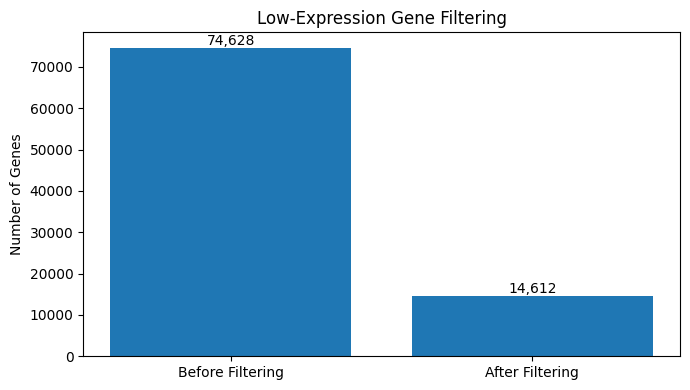

In [62]:
# Compare gene counts before and after filtering

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))

bars = ax.bar(
    ["Before Filtering", "After Filtering"],
    [genes_before, genes_after]
)

ax.set_ylabel("Number of Genes")
ax.set_title("Low-Expression Gene Filtering")

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

## 2.3 Quality control checks
Check for missing values and for samples that look like outliers. Keep the column order identical to `meta`.

In [88]:
assert expr_log.shape == (14612, 818), f"Unexpected shape: {expr_log.shape}"
assert not expr_log.isna().any().any(), "Missing values found in expr_log!"
assert np.isfinite(expr_log.to_numpy()).all(), "Infinite values found in expr_log!"
assert list(expr_log.columns) == list(meta.index), "Sample IDs are out of order!"

sample_medians = expr_log.median(axis=0)
print(f"QC Passed! Sample median log2(TPM+1) range: {sample_medians.min():.2f} to {sample_medians.max():.2f}")




QC Passed! Sample median log2(TPM+1) range: 1.95 to 3.75


## 2.4 Save the preprocessed matrix

In [89]:
# expr_log.to_parquet(f'{PROCESSED}/stage2_log2_filtered.parquet')
# assert list(expr_log.columns) == list(meta.index)

expr_log.to_parquet(f'{PROCESSED}/stage2_log2_filtered.parquet')
assert os.path.exists(f'{PROCESSED}/stage2_log2_filtered.parquet')
print("Saved stage2_log2_filtered.parquet successfully.")

Saved stage2_log2_filtered.parquet successfully.


# Stage 4: Exploratory data analysis

**Input:** `stage2_log2_filtered.parquet`, `meta`
**Output:** figures saved to `data/processed/` with the prefix `stage4_`

## 4.1 Distributions of ischemic time and RIN

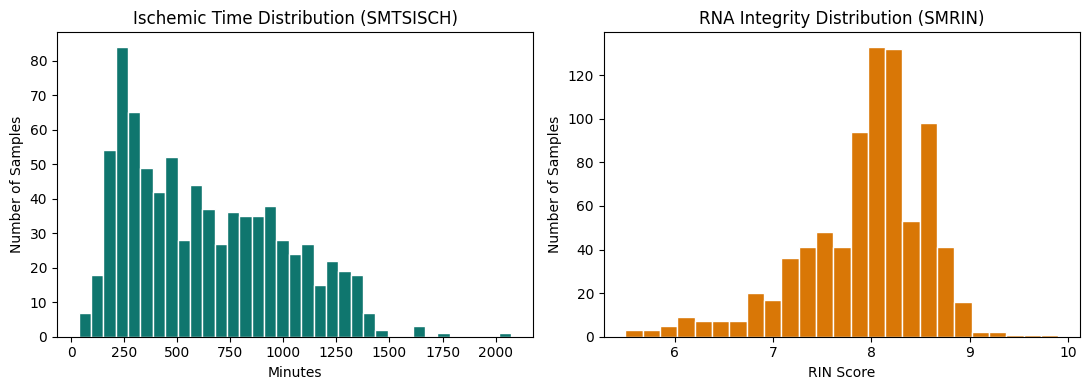

Ischemic time — Median: 573 min | Range: 35–2075 min
RIN score     — Median: 8.00 | Range: 5.50–9.90


In [91]:
# Load the cleaned matrix saved in Stage 2.4
expr_log = pd.read_parquet(f'{PROCESSED}/stage2_log2_filtered.parquet')

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(meta['ischemic_min'], bins=35, color='#0f766e', edgecolor='white')
axes[0].set(title='Ischemic Time Distribution (SMTSISCH)', xlabel='Minutes', ylabel='Number of Samples')

axes[1].hist(meta['rin'], bins=25, color='#d97706', edgecolor='white')
axes[1].set(title='RNA Integrity Distribution (SMRIN)', xlabel='RIN Score', ylabel='Number of Samples')

plt.tight_layout()
plt.savefig(f'{PROCESSED}/stage4_1_distributions.png', dpi=150)
plt.show()

print(f"Ischemic time — Median: {meta['ischemic_min'].median():.0f} min | Range: {meta['ischemic_min'].min():.0f}–{meta['ischemic_min'].max():.0f} min")
print(f"RIN score     — Median: {meta['rin'].median():.2f} | Range: {meta['rin'].min():.2f}–{meta['rin'].max():.2f}")

## 4.2 PCA of the samples
Colour the samples by ischemic time and by RIN. Check whether the main components follow ischemic time or something else, such as `SMGEBTCH` (batch) or `SMCENTER` (collection site).

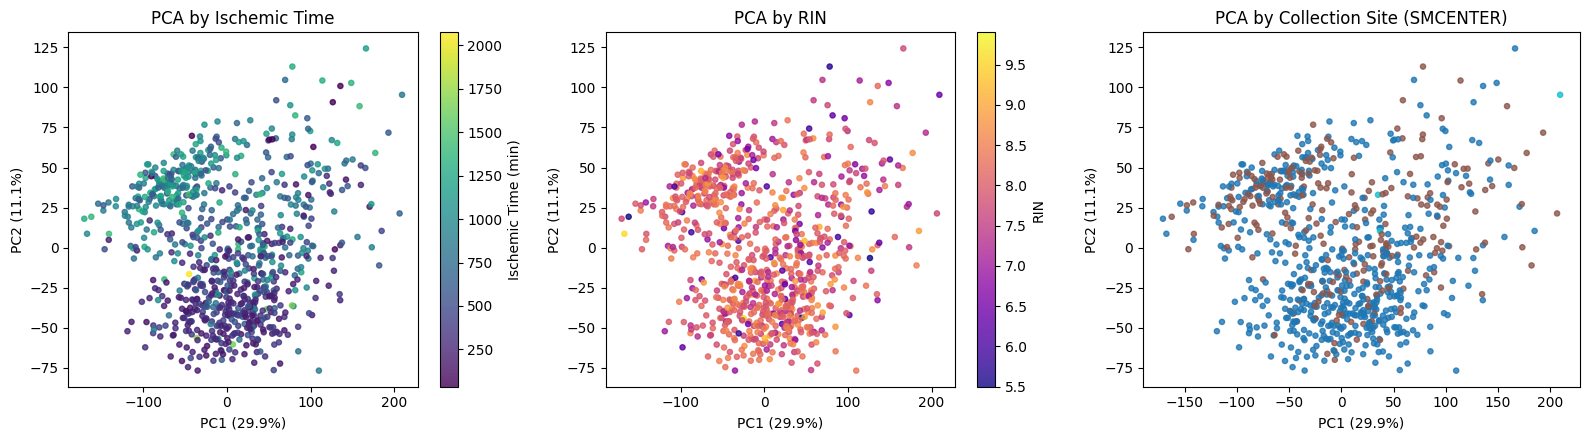

In [92]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(expr_log.T)
pca = PCA(n_components=2, random_state=SEED)
pcs = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_ * 100

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sc1 = axes[0].scatter(pcs[:, 0], pcs[:, 1], c=meta['ischemic_min'], cmap='viridis', s=14, alpha=0.8)
plt.colorbar(sc1, ax=axes[0], label='Ischemic Time (min)')
axes[0].set(title='PCA by Ischemic Time', xlabel=f'PC1 ({var_exp[0]:.1f}%)', ylabel=f'PC2 ({var_exp[1]:.1f}%)')

sc2 = axes[1].scatter(pcs[:, 0], pcs[:, 1], c=meta['rin'], cmap='plasma', s=14, alpha=0.8)
plt.colorbar(sc2, ax=axes[1], label='RIN')
axes[1].set(title='PCA by RIN', xlabel=f'PC1 ({var_exp[0]:.1f}%)', ylabel=f'PC2 ({var_exp[1]:.1f}%)')

if 'SMCENTER' in meta.columns:
    centers = meta['SMCENTER'].fillna('Unknown').astype('category')
    axes[2].scatter(pcs[:, 0], pcs[:, 1], c=centers.cat.codes, cmap='tab10', s=14, alpha=0.8)
    axes[2].set(title='PCA by Collection Site (SMCENTER)', xlabel=f'PC1 ({var_exp[0]:.1f}%)', ylabel=f'PC2 ({var_exp[1]:.1f}%)')

plt.tight_layout()
plt.savefig(f'{PROCESSED}/stage4_2_pca.png', dpi=150)
plt.show()

## 4.3 Correlation of ischemic time with RNA quality

In [67]:
# Your code here

## 4.4 Summary of observations

In [68]:
# Your code here

# Stage 5: Differential expression (PMI-sensitive genes)

**Input:** `stage2_log2_filtered.parquet`, `meta`, `train_ids`
**Output:** `data/processed/stage5_de_results.csv` (gene ID, symbol, effect size, p-value, FDR) and `data/processed/stage5_top_genes.csv` (genes with FDR < 0.05, ranked)

Fit on the training samples only (`train_ids`). Stage 6 tests the models on the held-out samples, so the gene list must never have seen them.

## 5.1 Select the training samples

In [69]:
# Your code here

## 5.2 Test each gene against ischemic time
Use linear regression or ANOVA across ischemic time groups. Decide whether to adjust for RIN and write the decision here.

In [70]:
# Your code here

## 5.3 Multiple testing correction
Apply Benjamini-Hochberg correction to the p-values.

In [71]:
# Your code here

## 5.4 Select and save the top genes

In [72]:
# Your code here

# Stage 6: Machine learning and baseline modelling

**Input:** `meta`, `X`, `y`, `train_ids`, `test_ids`, `stage5_top_genes.csv`
**Output:** `data/processed/stage6_metrics.csv` (model, R², RMSE on the test set) and the predicted-versus-actual plots

## 6.1 Prepare training and test sets

In [90]:
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import cross_validate

# Load the cleaned log2-filtered matrix saved in Stage 2.4
expr_log = pd.read_parquet(f'{PROCESSED}/stage2_log2_filtered.parquet')

# Inputs (X): cleaned 14,612 genes transposed to (samples x genes)
X_train = expr_log.T.loc[train_ids]
X_test = expr_log.T.loc[test_ids]

# Targets (y): actual ischemic time in minutes (already correct!)
y_train = y.loc[train_ids]
y_test = y.loc[test_ids]

# For RIN-only baseline features
rin_train = meta.loc[train_ids, ["rin"]]
rin_test = meta.loc[test_ids, ["rin"]]

groups_train = meta.loc[train_ids, "donor_id"]

# Integrity & leakage checks
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert X_train.index.equals(rin_train.index)
assert X_test.index.equals(rin_test.index)

assert set(train_ids).isdisjoint(set(test_ids))
assert set(meta.loc[train_ids, "donor_id"]).isdisjoint(set(meta.loc[test_ids, "donor_id"]))
assert y_train.notna().all() and y_test.notna().all()

# 5-fold donor-aware cross-validation
cv = GroupKFold(n_splits=5)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Gene features:", X_train.shape[1])
print("CV strategy: GroupKFold (5 folds)")
print("Sample/donor leakage check: PASSED")

Training samples: 654
Testing samples: 164
Gene features: 14612
CV strategy: GroupKFold (5 folds)
Sample/donor leakage check: PASSED


## 6.2 Baseline model: RIN only
Predict `ischemic_min` from `rin` alone.

Using Linear regression because it creates an interpretable model that predicts ischemic time using a single biological measurement: RNA Integrity Number.

In [74]:
# Linear regression
rin_baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("regression", LinearRegression())
])

# 5-fold cross-validation
baseline_cv = cross_validate(
    rin_baseline,
    rin_train,
    y_train,
    groups=groups_train,
    cv=cv,
    scoring={
        "rmse": "neg_root_mean_squared_error",
        "mae": "neg_mean_absolute_error",
        "r2": "r2"
    },
    n_jobs=1
)

cv_results = pd.DataFrame({
    "Fold": range(1, 6),
    "RMSE (min)": -baseline_cv["test_rmse"],
    "MAE (min)": -baseline_cv["test_mae"],
    "R²": baseline_cv["test_r2"]
})

display(cv_results.round(3))

print("Mean CV RMSE:",
      round(cv_results["RMSE (min)"].mean(), 2), "minutes")

print("Mean CV MAE:",
      round(cv_results["MAE (min)"].mean(), 2), "minutes")

print("Mean CV R²:",
      round(cv_results["R²"].mean(), 3))

rin_baseline.fit(rin_train, y_train)

print("RIN baseline trained successfully.")


,Fold,RMSE (min),MAE (min),R²
0,1,356.500,296.677,-0.021
1,2,396.128,336.227,-0.009
2,3,358.779,308.084,0.011
3,4,350.178,303.158,0.027
4,5,379.590,330.740,-0.000


Mean CV RMSE: 368.24 minutes
Mean CV MAE: 314.98 minutes
Mean CV R²: 0.001
RIN baseline trained successfully.


##Evaluation on Held-Out Test set

In [75]:

# Stage 6.2 — Final Baseline Evaluation

baseline_predictions = rin_baseline.predict(rin_test)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_r2 = r2_score(
    y_test, baseline_predictions
)

baseline_metrics = pd.DataFrame([{
    "model": "RIN-only Linear Regression",
    "R2": baseline_r2,
    "RMSE": baseline_rmse,
    "MAE": baseline_mae
}])

display(baseline_metrics.round(3))

# Save separately so Section 6.5 can consolidate all models
baseline_metrics.to_csv(
    f"{PROCESSED}/stage6_baseline_metrics.csv",
    index=False
)

baseline_results = pd.DataFrame({
    "sample_id": y_test.index,
    "actual_ischemic_min": y_test.to_numpy(),
    "predicted_ischemic_min": baseline_predictions
})

baseline_results.to_csv(
    f"{PROCESSED}/stage6_baseline_predictions.csv",
    index=False
)

print("Baseline evaluation files saved.")


,model,R2,RMSE,MAE
0,RIN-only Linear Regression,0.059,335.899,284.51


Baseline evaluation files saved.


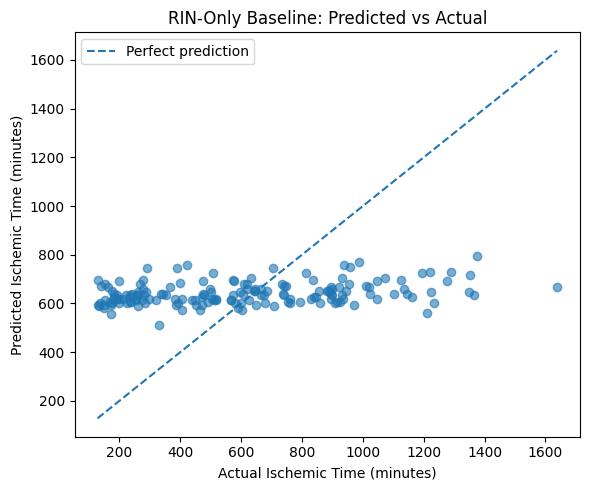

In [76]:

# RIN Baseline — Predicted vs Actual

import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

plt.scatter(
    y_test,
    baseline_predictions,
    alpha=0.6
)

limits = [
    min(y_test.min(), baseline_predictions.min()),
    max(y_test.max(), baseline_predictions.max())
]

plt.plot(limits, limits, "--", label="Perfect prediction")

plt.xlabel("Actual Ischemic Time (minutes)")
plt.ylabel("Predicted Ischemic Time (minutes)")
plt.title("RIN-Only Baseline: Predicted vs Actual")
plt.legend()
plt.tight_layout()

plt.savefig(
    f"{PROCESSED}/stage6_baseline_predictions.png",
    dpi=300
)

plt.show()


## 6.3 Ridge Regression on the top genes
Tune hyperparameters with cross-validation inside the training set only.

In [77]:
# Your code here

## 6.4 Random Forest on the top genes
Tune hyperparameters with cross-validation inside the training set only.

In [78]:
# Your code here

## 6.5 Compare models
Report R² and RMSE for every model on the same test set. RMSE is in minutes.

In [79]:
# Your code here

# Stage 7: Biological and pathway interpretation

**Input:** `stage5_de_results.csv`, `stage5_top_genes.csv`, `gene_annot`
**Output:** `data/processed/stage7_enrichment_up.csv` and `data/processed/stage7_enrichment_down.csv`, plus the main figures

## 7.1 Prepare the gene lists
The Ensembl IDs carry a version suffix (for example `ENSG...12`), which gene-set tools usually do not accept. Strip it, or use the symbols in `gene_annot`. Make separate lists for genes that rise and genes that fall with ischemic time, and keep all genes tested in Stage 5 as the background list.

In [80]:
# Your code here

## 7.2 Gene Ontology enrichment

In [81]:
# Your code here

## 7.3 KEGG pathway enrichment

In [82]:
# Your code here

## 7.4 Interpretation
Relate the enriched terms to the biology of oxygen deprivation and post-mortem change, based on the actual results.

In [83]:
# Your code here

# Stage 8: Synthesis, conclusions and final review

## 8.1 Summary of findings
Summarise the results of Stages 4 to 7 with the real numbers.

In [84]:
# Your code here

## 8.2 Limitations
Document the limits of the analysis, for example the single tissue and single cohort, donor-level factors that are not modelled, the weak link between RIN and ischemic time, possible batch and collection site effects, and that the model is not validated for forensic use.

In [85]:
# Your code here

## 8.3 Conclusions

In [86]:
# Your code here

## 8.4 Final checks
Confirm that variable names are consistent throughout (ischemic time is `SMTSISCH`), that the notebook runs from top to bottom, and that code and small results are pushed to GitHub.

In [87]:
# Your code here